# Chapter 1 · The standard model, revisited: interactive demos

Companion to Chapter 1 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/01-standard-model.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider

from mfe230d import bs
from mfe230d.paths import gbm_paths, time_grid
from mfe230d.standard import (fk_vasicek_check, girsanov_price, green, log_drift, max_relative_residuals,
                              transition_density, vasicek_bond)
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
TC = bs.TEST_CASE          # S = K = 100, T = 1, r = 1%, y = 2%, sigma = 20%
use_style()

## 1. One stock, two measures

Under the real-world measure $\mathbb P$ the stock grows at $\mu-y$; under the risk-neutral measure $\mathbb Q$ at $r-y$
(Definition 1.1 and Lemma 1.2). Both are driven by the same normals here, so each $\mathbb P$-path has a $\mathbb Q$-twin
that differs only by the drift. Left: a few paths of each. Middle: the two laws of $S_T$, with their exact densities.
Right: the call price estimated **from real-world samples**, each weighted by the density $Z_T=d\mathbb Q/d\mathbb P$, against
the Black–Scholes price (Proposition 1.3). The reweighted estimate is unbiased for every $\mu$, but its error grows as
$\mu$ moves away from $r$.

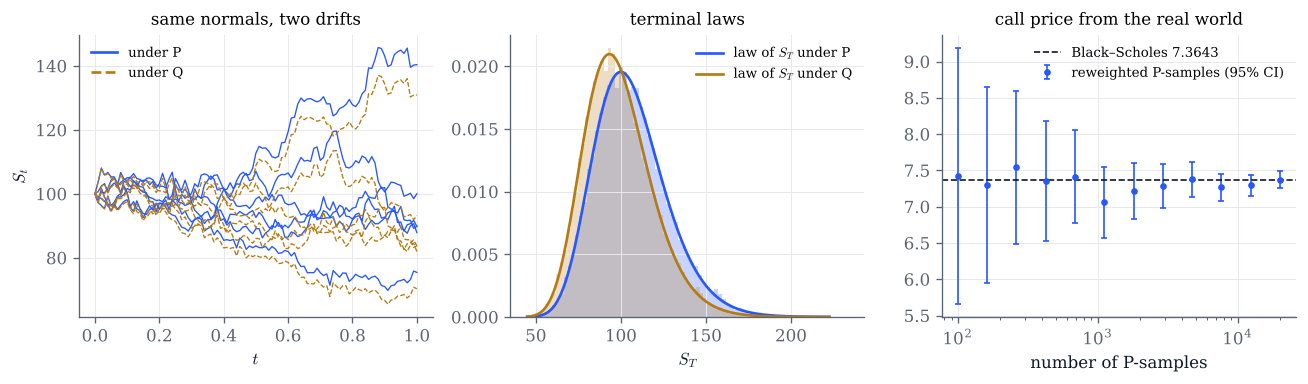

In [2]:
def two_measures(mu=0.08, sigma=0.2, r=0.01, y=0.02, T=1.0, n=20_000, seed=1):
    S0, K = TC["S"], TC["K"]
    t = time_grid(T, 100)
    Z = np.random.default_rng(seed).standard_normal((n, 100))
    P = gbm_paths(S0, t, r=mu, y=y, sigma=sigma, Z=Z)   # drift mu - y: the real world
    Q = gbm_paths(S0, t, r=r, y=y, sigma=sigma, Z=Z)    # drift r - y: the pricing world
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
    ax = axes[0]
    ax.plot(t, P[:6].T, color=COBALT, lw=0.8)
    ax.plot(t, Q[:6].T, color=GOLD, lw=0.8, ls="--")
    ax.plot([], [], color=COBALT, label="under P"); ax.plot([], [], color=GOLD, ls="--", label="under Q")
    ax.set(xlabel="$t$", ylabel="$S_t$", title="same normals, two drifts"); ax.legend(fontsize=8)

    ax = axes[1]
    grid = np.linspace(max(1.0, S0 * np.exp(-4 * sigma * np.sqrt(T))), S0 * np.exp(4 * sigma * np.sqrt(T)), 400)
    for paths, g, color, name in ((P, mu - y, COBALT, "P"), (Q, r - y, GOLD, "Q")):
        ax.hist(paths[:, -1], bins=80, density=True, color=color, alpha=0.25)
        ax.plot(grid, transition_density(grid, S0, T, g, sigma), color=color, label=f"law of $S_T$ under {name}")
    ax.set(xlabel="$S_T$", title="terminal laws"); ax.legend(fontsize=8)

    ax = axes[2]
    exact = float(bs.call(S0, K, T, r, y, sigma))
    ns = np.unique(np.logspace(2, np.log10(n), 12).astype(int))
    est = [girsanov_price(lambda s: np.maximum(s - K, 0.0), S0, T, mu, r, y, sigma, n=k, seed=seed + 7) for k in ns]
    m = np.array([e["mean"] for e in est]); se = np.array([e["se"] for e in est])
    ax.errorbar(ns, m, yerr=1.96 * se, color=COBALT, marker="o", ms=3, lw=0, elinewidth=1, capsize=2,
                label="reweighted P-samples (95% CI)")
    ax.axhline(exact, color=INK, lw=1, ls="--", label=f"Black–Scholes {exact:.4f}")
    ax.set(xscale="log", xlabel="number of P-samples", title="call price from the real world"); ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()

two_measures()

In [3]:
# Explore: the price never depends on mu, but how efficiently P-samples estimate it does.
interact(two_measures,
         mu=FloatSlider(value=0.08, min=-0.2, max=0.4, step=0.01, continuous_update=False, description="μ"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.8, step=0.01, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.01, min=-0.02, max=0.1, step=0.005, continuous_update=False, description="r"),
         y=FloatSlider(value=0.02, min=0.0, max=0.1, step=0.005, continuous_update=False, description="y"),
         T=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="T"),
         n=IntSlider(value=20_000, min=1_000, max=100_000, step=1_000, continuous_update=False, description="samples"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 2. Feynman–Kac by simulation

A zero-coupon bond when the short rate is an Ornstein–Uhlenbeck process, $dX=\kappa(\bar x-X)\,dt+\gamma\,dW$, discounted at
the state-dependent rate $r(t,x)=x$ (Example 1.9). The pricing equation has the closed-form solution
$u=e^{A(T-t)-B(T-t)x}$; Theorem 1.6, under its hypothesis (a), says that $u(0,x_0)=\mathbb E[e^{-\int_0^T X_s\,ds}]$.
Left: the solution of the equation as a function of the initial rate, with Monte Carlo estimates (exact OU paths,
trapezoid rule for the integral). Right: Monte Carlo minus the equation, with 95% confidence intervals.

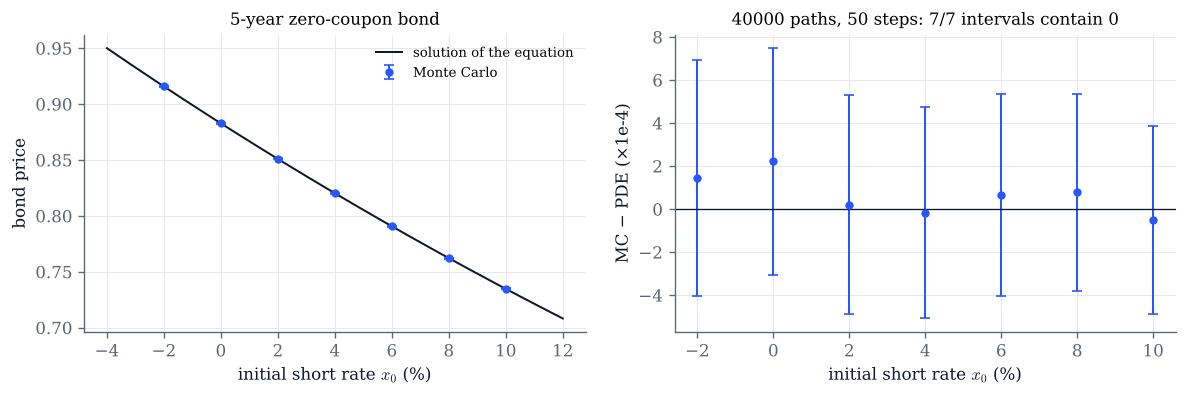

In [4]:
def feynman_kac(kappa=0.5, theta=0.04, xi=0.02, T=5.0, n_steps=50, n_paths=40_000, seed=2026):
    x0s = np.linspace(-0.02, 0.10, 7)
    rows = [fk_vasicek_check(x0, T, kappa, theta, xi, n_steps=n_steps, n_paths=n_paths, seed=seed + i)
            for i, x0 in enumerate(x0s)]
    grid = np.linspace(-0.04, 0.12, 200)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(100 * grid, vasicek_bond(grid, T, kappa, theta, xi), color=INK, lw=1.2, label="solution of the equation")
    ax.errorbar(100 * x0s, [r["mean"] for r in rows], yerr=[1.96 * r["se"] for r in rows], color=COBALT,
                marker="o", ms=4, lw=0, elinewidth=1.2, capsize=3, label="Monte Carlo")
    ax.set(xlabel="initial short rate $x_0$ (%)", ylabel="bond price", title=f"{T:g}-year zero-coupon bond")
    ax.legend(fontsize=8)
    ax2.errorbar(100 * x0s, [1e4 * r["error"] for r in rows], yerr=[1e4 * 1.96 * r["se"] for r in rows],
                 color=COBALT, marker="o", ms=4, lw=0, elinewidth=1.2, capsize=3)
    ax2.axhline(0, color=INK, lw=0.8)
    inside = sum(abs(r["error"]) < 1.96 * r["se"] for r in rows)
    ax2.set(xlabel="initial short rate $x_0$ (%)", ylabel="MC − PDE (×1e-4)",
            title=f"{n_paths} paths, {n_steps} steps: {inside}/7 intervals contain 0")
    fig.tight_layout(); plt.show()

feynman_kac()

In [5]:
# Explore: few steps make the trapezoid rule biased; few paths make the intervals wide.
# (theta is the long-run level x̄ of the notes, xi the volatility γ.)
interact(feynman_kac,
         kappa=FloatSlider(value=0.5, min=0.05, max=3.0, step=0.05, continuous_update=False, description="κ"),
         theta=FloatSlider(value=0.04, min=-0.01, max=0.10, step=0.005, continuous_update=False, description="x̄"),
         xi=FloatSlider(value=0.02, min=0.0025, max=0.06, step=0.0025, continuous_update=False, description="γ"),
         T=FloatSlider(value=5.0, min=0.5, max=30.0, step=0.5, continuous_update=False, description="T"),
         n_steps=IntSlider(value=50, min=1, max=200, continuous_update=False, description="steps"),
         n_paths=IntSlider(value=40_000, min=2_000, max=100_000, step=2_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 3. A delta, a step and a ramp

As functions of the strike $K$, the Arrow–Debreu price density $G(0,S_0;T,K)$, the digital call and the call are each
minus the strike derivative of the next (Remark 1.14). As the maturity shrinks they approach the Dirac delta at $S_0$,
the step $\mathbf 1_{\{K<S_0\}}$ and the ramp $(S_0-K)^+$ (Proposition 1.12 and Figure 1.2). The area under the
first curve is $e^{-rT}$ for every $T$.

<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:9: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_19344/4107822618.py:9: SyntaxWarning: invalid escape sequence '\d'
  axes[0].axvline(S0, color=INK, ls="--", lw=0.8, label="where $\delta_{S_0}$ sits")


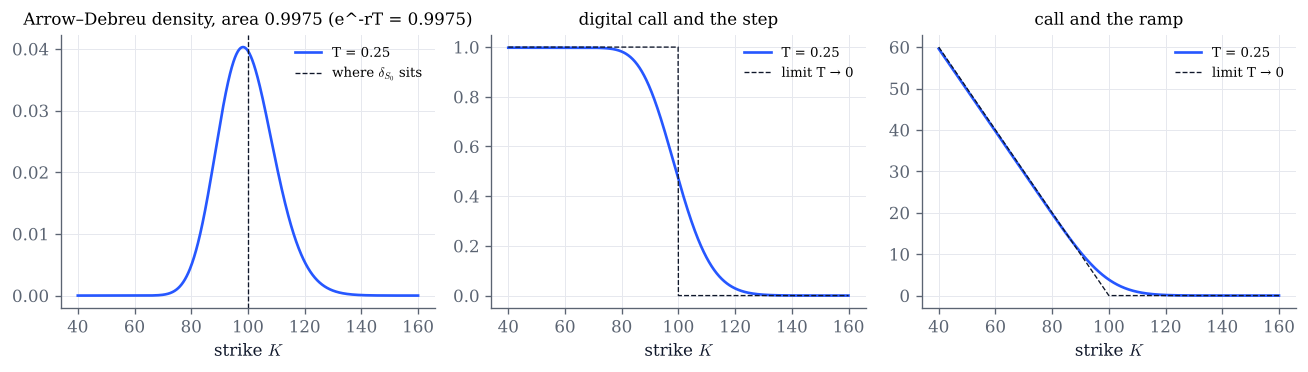

In [6]:
def dirac(T=0.25, sigma=0.2, r=0.01, y=0.02):
    S0 = TC["S"]
    K = np.linspace(40, 160, 1201)
    G = green(K, S0, T, r, y, sigma)
    D = bs.digital_call(S0, K, T, r, y, sigma)
    C = bs.call(S0, K, T, r, y, sigma)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
    axes[0].plot(K, G, color=COBALT, label=f"T = {T:.3g}")
    axes[0].axvline(S0, color=INK, ls="--", lw=0.8, label="where $\delta_{S_0}$ sits")
    axes[0].set(title=f"Arrow–Debreu density, area {np.trapezoid(G, K):.4f} (e^-rT = {np.exp(-r * T):.4f})")
    axes[1].plot(K, D, color=COBALT, label=f"T = {T:.3g}")
    axes[1].plot(K, np.where(K < S0, 1.0, 0.0), color=INK, ls="--", lw=0.8, label="limit T → 0")
    axes[1].set(title="digital call and the step")
    axes[2].plot(K, C, color=COBALT, label=f"T = {T:.3g}")
    axes[2].plot(K, np.maximum(S0 - K, 0.0), color=INK, ls="--", lw=0.8, label="limit T → 0")
    axes[2].set(title="call and the ramp")
    for ax in axes:
        ax.set_xlabel("strike $K$")
        ax.legend(fontsize=8, loc="upper right")
    fig.tight_layout(); plt.show()

dirac()

In [7]:
# Explore: drag T towards zero (log scale) and watch the three curves sharpen.
interact(dirac,
         T=FloatLogSlider(value=0.25, base=10, min=-3, max=1, step=0.05, continuous_update=False, description="T"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.8, step=0.01, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.01, min=-0.02, max=0.1, step=0.005, continuous_update=False, description="r"),
         y=FloatSlider(value=0.02, min=0.0, max=0.1, step=0.005, continuous_update=False, description="y"));

## 4. Checking the backward and forward equations

The Green's function solves the pricing equation in the starting point $(t,x)$ and the adjoint equation in the
arrival point $(T,\xi)$ (Proposition 1.12). Replace every derivative by a central difference with relative step $h$
and evaluate both residuals on a grid of points: the largest relative residual falls like $h^2$ (truncation) until
rounding errors, which grow as $h$ shrinks, take over (Figure 1.1, right). The marker shows the best step on this grid.

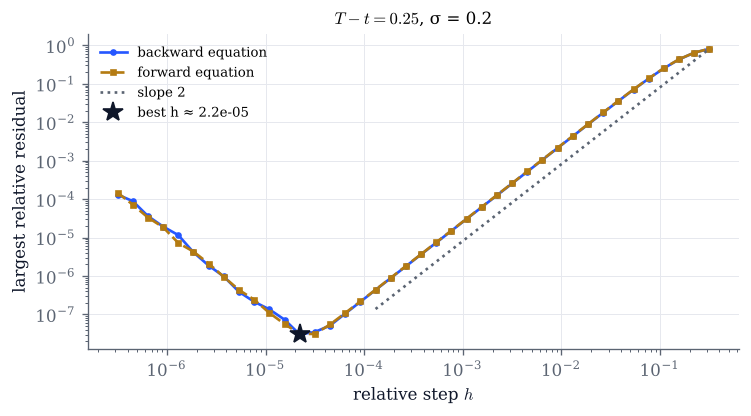

In [8]:
def residuals(tau=0.25, sigma=0.2, r=0.01, y=0.02):
    hs = np.logspace(-6.5, -0.5, 40)
    back, fwd = max_relative_residuals(hs, tau=tau, r=r, y=y, sigma=sigma)
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.loglog(hs, back, color=COBALT, marker="o", ms=3, label="backward equation")
    ax.loglog(hs, fwd, color=GOLD, ls="--", marker="s", ms=3, label="forward equation")
    ref = hs[hs > 1e-4]
    ax.loglog(ref, back[-1] * (ref / hs[-1]) ** 2, color=GREY, ls=":", label="slope 2")
    i = np.argmin(back)
    ax.plot(hs[i], back[i], marker="*", ms=12, color=INK, lw=0, label=f"best h ≈ {hs[i]:.1e}")
    ax.set(xlabel="relative step $h$", ylabel="largest relative residual", title=f"$T-t={tau:g}$, σ = {sigma:g}")
    ax.legend(fontsize=8); plt.show()

residuals()

In [9]:
interact(residuals,
         tau=FloatLogSlider(value=0.25, base=10, min=-3, max=1, step=0.1, continuous_update=False, description="T−t"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.8, step=0.01, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.01, min=-0.02, max=0.1, step=0.005, continuous_update=False, description="r"),
         y=FloatSlider(value=0.02, min=0.0, max=0.1, step=0.005, continuous_update=False, description="y"));

## Things to try

- In section 1, set $\mu=r$. What are the weights $Z_T$ then, and what happens to the error bars? Now push $\mu$ to $40\%$:
  the estimate stays unbiased, so why does it become so noisy?
- In section 2, take a single time step. The paths of $X$ are still exact; where does the bias come from, and why does it
  grow with $\gamma$ and $T$?
- In section 2, set $\bar x<0$ and start below zero. Discounting at a negative rate makes the bond worth more than $1$;
  which hypothesis of Theorem 1.6 does the example rely on, and why not the other one?
- In section 3, at $K=S_0$ the digital is worth roughly one half whatever the maturity. Why not exactly $e^{-rT}/2$? (Look at $d_-$.)
- In section 4, make $T-t$ very small. The residuals grow at every $h$: which derivatives of $G$ become large, and why does
  that matter for a finite-difference check?